# Un breve análisis de un grupo de WhatsApp

A través de esta libreta exploraremos los mensajes de un grupo de WhatsApp del **6 de noviembre de 2025 al 24 de septiembre de 2026**, aunque el grupo fue creado a mediados de 2022. Ese salto se debe al cambio de celular: quedaron tres registros antiguos y el historial posterior al cambio.

El grupo está confromado por personas con el mismo interés: afición al mismo equipo de futbol. 

Los remitentes se identifican con alias de Pokémon de primera generación. La tabla conserva el contenido para analizarlo localmente; las salidas muestran resultados agregados.

Además de conocer quiénes participan y cómo conversan, investigaremos si los días con más mensajes coinciden con partidos de Pumas y qué ocurrió en otras fechas destacadas.

## 1. Fuente y configuración

**Fuente:** exportación manual guardada en `data/raw/chat.txt`.

**Periodo conservado:** desde el 6 de noviembre de 2025. Las horas de la exportación corresponden mayormente a **Hermosillo (UTC−7)**.

**Ejecución:** se van a correr las celdas de arriba hacia abajo. Las listas privadas `noimportantes.txt` y `altisonantes.txt` se leen desde `data/interim/`. Para los adjetivos se utiliza el modelo `es_core_news_md` de spaCy, instalado durante la exploración.

### 1.1 Bibliotecas y rutas

In [1]:
from pathlib import Path
from collections import Counter
from datetime import datetime
import re

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import emoji
import spacy
from spacy.lang.es.stop_words import STOP_WORDS
from wordcloud import WordCloud
from PIL import Image
from IPython.display import display

project_dir = next(
    ruta for ruta in (Path.cwd(), *Path.cwd().parents)
    if (ruta / "data" / "raw" / "chat.txt").is_file()
)
raw_dir = project_dir / "data" / "raw"
inicio_historial = pd.Timestamp("2025-11-06")
dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
                     "axes.spines.right": False})

### 1.2 Listas de palabras

`noimportantes.txt` contiene términos que excluimos del vocabulario mostrado debido a su nulo enriquecimiento de lo buscado; `altisonantes.txt` contiene palabras que presentamos con asteriscos, de forma de censura, por su contenido un poco "elevado".

In [2]:
# Definiremos una función que permita leerlos archivos de apoyo intermedio
def leer_palabras(nombre_archivo):
    ruta = project_dir / "data" / "interim" / nombre_archivo
    return {
        linea.strip().casefold()
        for linea in ruta.read_text(encoding="utf-8-sig").splitlines()
        if linea.strip() and not linea.lstrip().startswith("#")
    }

no_importantes = leer_palabras("noimportantes.txt") # Estas serán eliminadasa
altisonantes = leer_palabras("altisonantes.txt") # Estas serán censuradas

#Función para censurar las palabrotas
def censurar(palabra):
    if palabra not in altisonantes:
        return palabra
    if len(palabra) <= 2:
        return "*" * len(palabra)
    return palabra[0] + "*" * (len(palabra) - 2) + palabra[-1]

def tokenizar(contenido):
    return re.findall(r"[^\W\d_]+", contenido.casefold())

def filtrar_frecuencias(conteo):
    return Counter({p: n for p, n in conteo.items()
                    if p not in STOP_WORDS and p not in no_importantes})

def mostrar_frecuencias(conteo, medida, limite=20):
    # Los empates se ordenan alfabéticamente para obtener salidas estables.
    filas = sorted(conteo.items(), key=lambda par: (-par[1], par[0]))[:limite]
    resultado = pd.DataFrame(filas, columns=["palabra", medida])
    resultado["palabra"] = resultado["palabra"].map(censurar)
    display(resultado)

## 2. Preparación y calidad de datos

### 2.1 Lectura del chat

Durante pruebas y examianción manual se identificó el formato como `día/mes/año, hora:minuto:segundo a. m./p. m.`. Cada encabezado iniciará un mensaje; las líneas siguientes forman parte del mismo contenido hasta encontrar otro encabezado para comenzar otro mensaje; así, sucesivamente.

In [3]:
def convertir_fecha(marca):
    marca = marca.replace("\u202f", " ").replace("\u00a0", " ")
    marca = re.sub(r"\s*a\.\s*m\.", " AM", marca, flags=re.I)
    marca = re.sub(r"\s*p\.\s*m\.", " PM", marca, flags=re.I)
    return datetime.strptime(marca, "%d/%m/%y, %I:%M:%S %p")

patron_completo = re.compile(
    r"^\[(?P<marca>[^\]]+)\]\s+(?P<usuario>[^:]+):\s?(?P<contenido>.*)$"
)
mensajes = []
lineas_previas = 0
total_lineas = 0

with (raw_dir / "chat.txt").open(encoding="utf-8-sig") as archivo:
    for numero, linea in enumerate(archivo, start=1):
        total_lineas += 1
        linea = linea.rstrip("\r\n")
        encabezado = patron_completo.match(linea)
        if encabezado:
            try:
                fecha = convertir_fecha(encabezado.group("marca"))
            except ValueError:
                raise ValueError(f"Fecha no reconocida en la línea {numero}.") from None
            mensajes.append({
                "timestamp": fecha,
                "usuario_original": encabezado.group("usuario"),
                "contenido": encabezado.group("contenido"),
                "lineas": 1,
            })
        elif mensajes:
            mensajes[-1]["contenido"] += "\n" + linea
            mensajes[-1]["lineas"] += 1
        else:
            lineas_previas += 1

print(f"Líneas: {total_lineas:,} | Mensajes: {len(mensajes):,}")
print(f"Mensajes de varias líneas: {sum(m['lineas'] > 1 for m in mensajes):,}")
assert lineas_previas == 0, "Hay líneas anteriores al primer encabezado."

Líneas: 137,560 | Mensajes: 108,842
Mensajes de varias líneas: 17,785


### 2.2 Alias y tabla de mensajes

Se asignará un *Pokemon* por persona. `Grupo` y `Meta IA` se distinguen de los participantes humanos, ya que quedaron mensajes de registro de creación del grupo y diversas solicitudes a la IA de Meta para interactura dentro del grupo.

In [4]:
usuarios_unicos = sorted({m["usuario_original"] for m in mensajes})

# Asignación de un alias a cada identificador U01–U30.
alias_ordenados = [
    "Cubone", "Grupo", "Magneton", "Meta IA", "Pidgeotto",
    "Machoke", "Lickitung", "Arbok", "Slowpoke", "Growlithe",
    "Diglett", "Kingler", "Magikarp", "Mewtwo", "Butterfree",
    "Seel", "Gastly", "Tangela", "Jynx", "Kabutops",
    "Voltorb", "Psyduck", "Scyther", "Electabuzz", "Golduck",
    "Squirtle", "Koffing", "Doduo", "Mankey", "Alakazam",
]

# Vinculamis los alias con los remitentes ordenados
assert len(alias_ordenados) == len(usuarios_unicos) == 30
assert len(set(alias_ordenados)) == 30
alias_por_usuario = dict(zip(usuarios_unicos, alias_ordenados, strict=True))

print(f"Alias preparados: {len(alias_por_usuario)}")

Alias preparados: 30


In [5]:
# Se construye la tabla usando solo alias en la columna de remitente.
tabla = pd.DataFrame({
    "timestamp": [m["timestamp"] for m in mensajes],
    "usuario": [alias_por_usuario[m["usuario_original"]] for m in mensajes],
    "contenido": [m["contenido"] for m in mensajes],
    "lineas": [m["lineas"] for m in mensajes],
})

# Aislamos de los participantes humanos los mensajes del grupo (el registro de creación) y de Meta IA.
tabla["tipo_remitente"] = "persona"
tabla.loc[tabla["usuario"] == "Grupo", "tipo_remitente"] = "grupo"
tabla.loc[tabla["usuario"] == "Meta IA", "tipo_remitente"] = "ia"

print(f"Filas: {len(tabla):,}")
print(f"Alias distintos: {tabla['usuario'].nunique()}")
print(f"Fechas faltantes: {tabla['timestamp'].isna().sum()}")

Filas: 108,842
Alias distintos: 30
Fechas faltantes: 0


### 2.3 Comprobaciones y orden temporal

Se registran los contenidos vacíos, las coincidencias exactas y los retrocesos de fecha. Conservamos los registros y ordenamos por fecha manteniendo su posición original como desempate.

In [6]:
calidad = pd.Series({
    "mensajes": len(tabla),
    "fechas_faltantes": int(tabla["timestamp"].isna().sum()),
    "contenidos_vacios": int(tabla["contenido"].str.strip().eq("").sum()),
    "registros_repetidos": int(tabla.duplicated(["timestamp", "usuario", "contenido"]).sum()),
    "retrocesos_originales": int(tabla["timestamp"].diff().dt.total_seconds().lt(0).sum()),
    "registros_anteriores_al_periodo": int(tabla["timestamp"].lt(inicio_historial).sum()),
}, name="cantidad")
display(calidad.to_frame())

tabla["orden_original"] = range(len(tabla))
tabla = tabla.sort_values(["timestamp", "orden_original"], kind="stable").reset_index(drop=True)
assert tabla["timestamp"].is_monotonic_increasing

,cantidad
mensajes,108842
fechas_faltantes,0
contenidos_vacios,5
registros_repetidos,5
retrocesos_originales,159
registros_anteriores_al_periodo,3


### 2.4 Tipos de contenido y selección de textos

Las marcas de multimedia permiten identificar mensajes con sticker, imagen, video o audio. Un mensaje puede contener varias marcas. Para contar palabras se utilizan los mensajes humanos sin estas marcas y se retiran los links de páginas web externas.

In [7]:
contenido_normalizado = (tabla["contenido"].str.replace("\u200e", "", regex=False)
                         .str.strip().str.casefold())
tipos = ["sticker", "imagen", "video", "audio"]
indicadores = pd.DataFrame({
    tipo: contenido_normalizado.str.contains(rf"\b{tipo}\s+omitid[oa]\b", na=False)
    for tipo in tipos
})
tabla["tipo_contenido"] = "sin_marcador"
for tipo in tipos:
    tabla[f"es_{tipo}"] = indicadores[tipo]
    tabla.loc[indicadores[tipo], "tipo_contenido"] = tipo
tabla.loc[indicadores.sum(axis=1) > 1, "tipo_contenido"] = "mixto"
tabla["num_emojis"] = tabla["contenido"].map(emoji.emoji_count)

es_texto = (
    tabla["tipo_remitente"].eq("persona")
    & tabla["tipo_contenido"].eq("sin_marcador")
    & ~contenido_normalizado.str.contains(r"omitid[oa]", na=False)
    & tabla["contenido"].str.strip().ne("")
)
textos = tabla.loc[es_texto].copy()
sin_enlaces = textos["contenido"].str.replace(r"https?://\S+", " ", regex=True)
textos["palabras"] = sin_enlaces.str.count(r"[^\W\d_]+")

display(tabla["tipo_contenido"].value_counts().rename("mensajes").to_frame())

,mensajes
tipo_contenido,
sin_marcador,94278
sticker,8786
imagen,3360
mixto,1124
audio,772
video,522


## 3. Participación

### 3.1 ¿Quién envía más mensajes?
Veamos en una tabla y en una gráfica de barras quiénes son los que contribuyen con más mensajes individuales.

In [8]:
# Contamos los mensajes por participante usando solo sus alias.
ranking_mensajes = (
    tabla.loc[tabla["tipo_remitente"] == "persona", "usuario"]
    .value_counts()
    .rename_axis("usuario")
    .reset_index(name="mensajes")
)

display(ranking_mensajes.head(10))

,usuario,mensajes
0,Lickitung,18190
1,Mewtwo,15271
2,Growlithe,9181
3,Tangela,8125
4,Magikarp,6551
5,Machoke,6491
6,Pidgeotto,5009
7,Koffing,4881
8,Diglett,4786
9,Doduo,4537


Es **Lickitung** quien encabeza el grupo con **18,190** mensajes, seguido de **Mewtwo** con **15,271**. En tercer puesto aparece **Growlithe**, quien registra cerca de la mitad de mensajes del más platicador de este grupo. Una diferencia a tomar en cuenta.

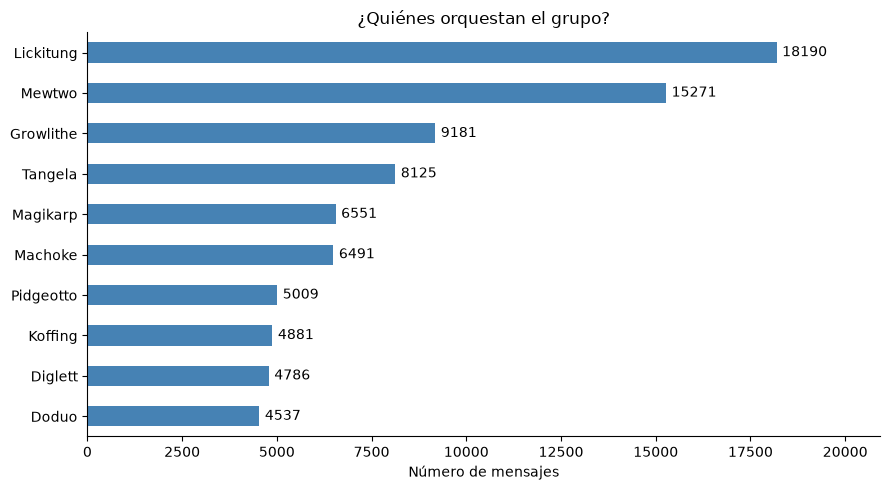

In [9]:
top10 = ranking_mensajes.head(10).sort_values("mensajes")

ax = top10.plot.barh(
    x="usuario", y="mensajes",
    figsize=(9, 5), color="steelblue", legend=False
)

ax.bar_label(ax.containers[0], padding=4, fmt="%.0f")
ax.set(
    title="¿Quiénes orquestan el grupo?",
    xlabel="Número de mensajes",
    ylabel=""
)
ax.set_xlim(0, top10["mensajes"].max() * 1.15)

plt.tight_layout()
plt.show()

### 3.2 Palabras por mensaje y palabras totales

In [10]:
# Calculamos el promedio por persona
promedio_palabras = (
    textos.groupby("usuario")["palabras"]
    .agg(mensajes_texto="size", promedio_palabras="mean")
    .sort_values("promedio_palabras", ascending=False)
    .round(2)
)

display(promedio_palabras)

,mensajes_texto,promedio_palabras
usuario,,
Pidgeotto,4580,9.92
Koffing,3914,9.71
Voltorb,5,9.60
Magneton,2412,9.56
Diglett,3916,9.27
Alakazam,903,9.00
Kabutops,3348,8.72
Mewtwo,13370,8.53
Machoke,5867,8.52


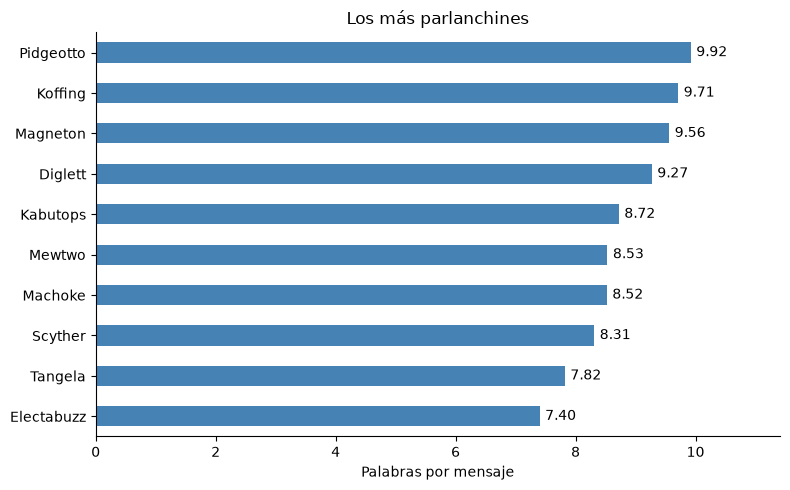

In [11]:
minimo_mensajes = 1000 # usaremos umbrales para no tomar en cuenta a los fantasmones

datos = (
    promedio_palabras[
        promedio_palabras["mensajes_texto"] >= minimo_mensajes
    ]
    .head(10)
    .sort_values("promedio_palabras")
)

ax = datos["promedio_palabras"].plot.barh(
    figsize=(8, 5), color="steelblue"
)
ax.bar_label(ax.containers[0], padding=4, fmt="%.2f")
ax.set(
    title="Los más parlanchines",
    xlabel="Palabras por mensaje",
    ylabel=""
)
ax.set_xlim(0, datos["promedio_palabras"].max() * 1.15)

plt.tight_layout()
plt.show()

**Pidgeotto** es quien más palabras escribe por mensaje: **9.92**, en **4,580** mensajes de texto. Le sigue **Koffing**, con **9.71**. Son los que más palabras, en promedio, le agregan a su mensaje. Se ha establecido un umbral de personas con mínimo 1000 mensajes para esto.

In [12]:
# Suma las palabras de los mensajes de texto por participante.
ranking_palabras = (
    textos.groupby("usuario")["palabras"]
    .sum()
    .sort_values(ascending=False)
    .rename("palabras")
)

display(ranking_palabras.head(10))

usuario
Mewtwo       114018
Lickitung    105243
Tangela       55320
Growlithe     54776
Machoke       49966
Pidgeotto     45450
Magikarp      41433
Koffing       38002
Diglett       36318
Kabutops      29204
Name: palabras, dtype: int64

Aunque no solo importa explayarse tanto cada cierto tiempo, sino con qué frecuencia lo haces. **Mewtwo**, si bien no figura en el top 5 de más parlanchines por mensaje, sí es uno de los líderes de mensajes de cualquier tipo, por lo que encabeca el total de palabras con **114,018 palabras**; **Lickitung** le sigue con **105,243**. Lickitung envió más mensajes, mientras que los mensajes de texto de Mewtwo fueron, en promedio, más largos.

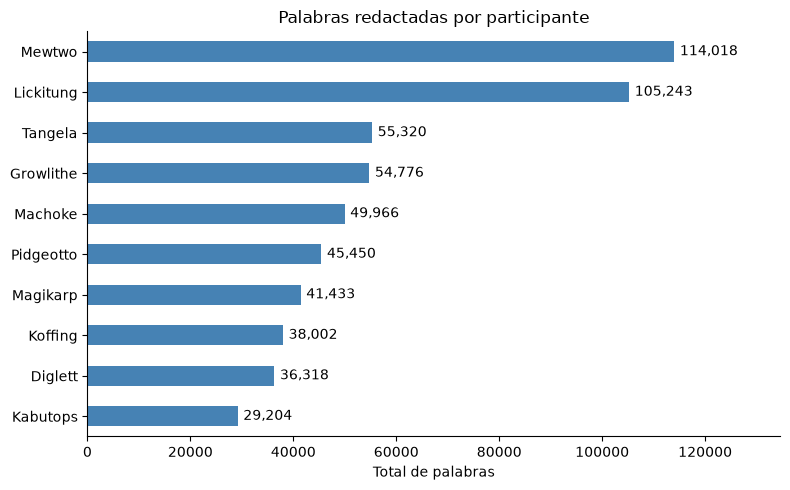

In [13]:
datos = ranking_palabras.head(10).sort_values()

ax = datos.plot.barh(figsize=(8, 5), color="steelblue")
ax.bar_label(
    ax.containers[0],
    labels=[f"{cantidad:,}" for cantidad in datos],
    padding=4
)
ax.set(
    title="Palabras redactadas por participante",
    xlabel="Total de palabras",
    ylabel=""
)
ax.set_xlim(0, datos.max() * 1.18)

plt.tight_layout()
plt.show()

### 3.3 ¿Quienes envían más mensajes de texto escriben más o menos palabras por mensaje?
Ya repasamos los que se hacen notar más y los que amplian su léxico al redactar. ¿Habrá alguna correlación entre estas dos variables?

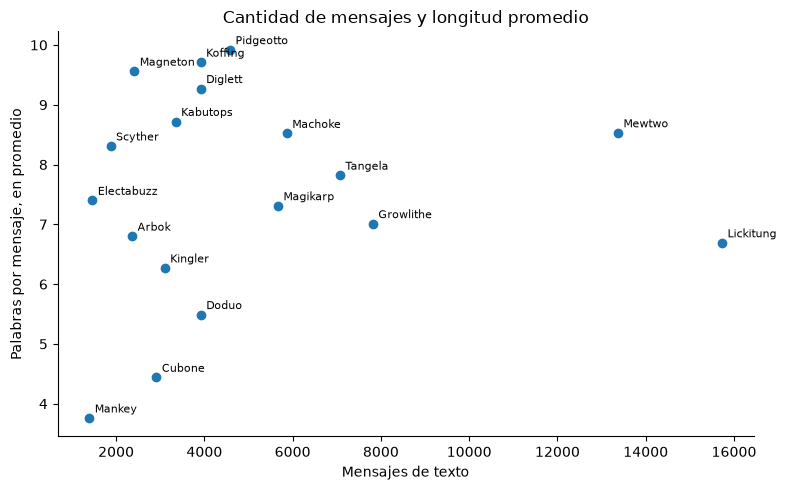

Correlación de Spearman: 0.17


In [14]:
datos = promedio_palabras[
    promedio_palabras["mensajes_texto"] >= 1000
]

correlacion = (
    datos["mensajes_texto"].rank()
    .corr(datos["promedio_palabras"].rank())
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(datos["mensajes_texto"], datos["promedio_palabras"])

for usuario, fila in datos.iterrows():
    ax.annotate(
        usuario,
        (fila["mensajes_texto"], fila["promedio_palabras"]),
        xytext=(4, 4), textcoords="offset points", fontsize=8
    )

ax.set(
    title="Cantidad de mensajes y longitud promedio",
    xlabel="Mensajes de texto",
    ylabel="Palabras por mensaje, en promedio"
)

plt.tight_layout()
plt.show()
print(f"Correlación de Spearman: {correlacion:.2f}")

Entre quienes enviaron al menos 1,000 mensajes de texto, la correlación de Spearman entre cantidad de mensajes y palabras promedio por mensaje fue de **0.17**. No se aprecia una tendencia clara: participantes con cantidades parecidas de mensajes tienen promedios de longitud muy distintos. En este grupo, enviar más mensajes no permite anticipar qué tan largos serán.

### 3.4 Emojis 

In [15]:
# Sumamos los emojis por participante
ranking_emojis = (
    tabla.loc[tabla["tipo_remitente"] == "persona"]
    .groupby("usuario")["num_emojis"]
    .sum()
    .sort_values(ascending=False)
    .rename("emojis")
)

display(ranking_emojis.head(10))

usuario
Growlithe    1507
Magikarp     1328
Machoke       593
Lickitung     589
Koffing       480
Diglett       329
Pidgeotto     322
Doduo         287
Mewtwo        267
Tangela       262
Name: emojis, dtype: int64

**Growlithe** es la persona que envió más emojis (1,507), seguido de **Magikarp** (1,328). Ambos, sacándole mucha diferencia al tercer y cuarto lugar,  **Machoke** y **Lickitung** que tienen cerca de un tercio de ellos. De nuevo, puede que exista una relación entre los que más se hacen presentes y la cantidad de emojis, por lo que será más atractivo observarlo en forma de tasa.

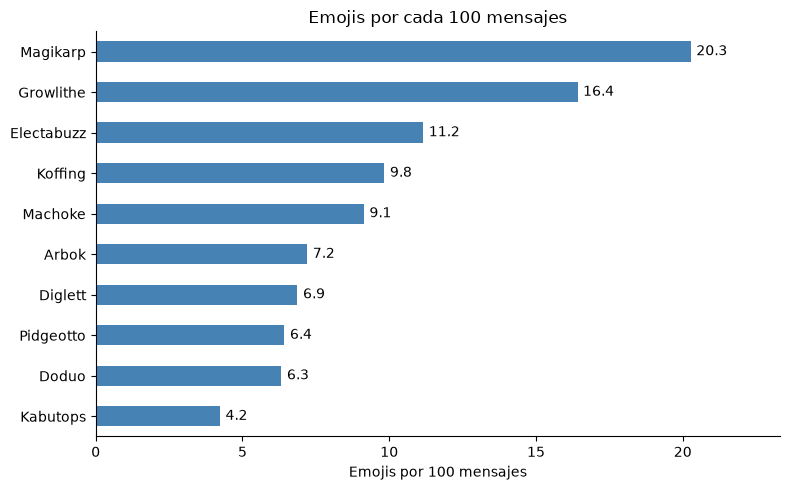

In [16]:
uso_emojis = ranking_mensajes.set_index("usuario").join(ranking_emojis)
uso_emojis = uso_emojis[uso_emojis["mensajes"] >= 1000].copy()
uso_emojis["por_100_mensajes"] = (
    uso_emojis["emojis"] / uso_emojis["mensajes"] * 100
)

datos = uso_emojis["por_100_mensajes"].nlargest(10).sort_values()

ax = datos.plot.barh(figsize=(8, 5), color="steelblue")
ax.bar_label(ax.containers[0], padding=4, fmt="%.1f")
ax.set(
    title="Emojis por cada 100 mensajes",
    xlabel="Emojis por 100 mensajes",
    ylabel=""
)
ax.set_xlim(0, datos.max() * 1.15)

plt.tight_layout()
plt.show()

Aquí es donde **Magikarp** y **Electabuzz** se hacen notar, pues aunque no son de los que más platican, sí son de los que más expresan su sentir através de los emojis.

### 3.5 Stickers

In [17]:
# Cuenta mensajes con la marca de sticker por participante.
ranking_stickers = (
    tabla.loc[tabla["tipo_remitente"] == "persona"]
    .groupby("usuario")["es_sticker"]
    .sum()
    .sort_values(ascending=False)
    .rename("mensajes_con_sticker")
)

display(ranking_stickers.head(10))

usuario
Lickitung    1773
Mewtwo       1073
Growlithe     930
Koffing       772
Cubone        755
Tangela       630
Diglett       619
Magikarp      497
Doduo         414
Kabutops      365
Name: mensajes_con_sticker, dtype: int64

**Lickitung** encabezó el uso de stickers con **1,773** mensajes, seguido de **Mewtwo** (1,073) y **Growlithe** (930). Los primeros puestos se repiten en varias medidas, aunque cada participante destaca de distinta manera. Aunque, recordemos que Cubone pocas veces manda mensaje, por lo que observaremos la tasa de stickers para detectarla como posible interactuadora de stickers.

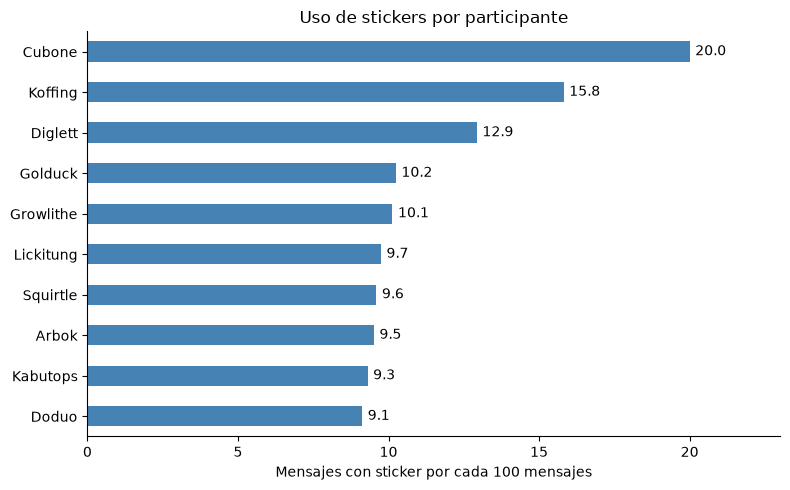

In [18]:
uso_stickers = ranking_mensajes.set_index("usuario").join(ranking_stickers)
uso_stickers = uso_stickers[uso_stickers["mensajes"] >= 500].copy()

uso_stickers["por_100_mensajes"] = (
    uso_stickers["mensajes_con_sticker"]
    / uso_stickers["mensajes"] * 100
)

datos = uso_stickers["por_100_mensajes"].nlargest(10).sort_values()

ax = datos.plot.barh(figsize=(8, 5), color="steelblue")
ax.bar_label(ax.containers[0], padding=4, fmt="%.1f")
ax.set(
    title="Uso de stickers por participante",
    xlabel="Mensajes con sticker por cada 100 mensajes",
    ylabel=""
)
ax.set_xlim(0, datos.max() * 1.15)

plt.tight_layout()
plt.show()

**Cubone** no será una persona muy expresiva textualmente, pero su estilo de vida son los *stickers*.

### 3.6 ¿Quién usa más stickers y quién usa más emojis como parte de sus mensajes?

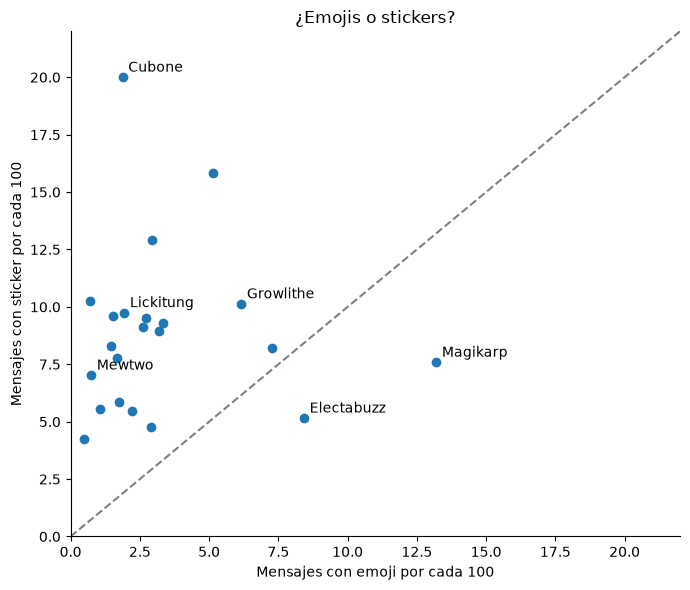

In [19]:
formas = (
    tabla.loc[tabla["tipo_remitente"] == "persona"]
    .groupby("usuario")
    .agg(
        mensajes=("usuario", "size"),
        con_emoji=("num_emojis", lambda serie: (serie > 0).sum()),
        con_sticker=("es_sticker", "sum")
    )
)

formas = formas[formas["mensajes"] >= 500].copy()
formas["emoji"] = 100 * formas["con_emoji"] / formas["mensajes"]
formas["sticker"] = 100 * formas["con_sticker"] / formas["mensajes"]

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(formas["emoji"], formas["sticker"])

for usuario in ["Cubone", "Growlithe", "Magikarp", "Lickitung", "Mewtwo","Electabuzz"]:
    fila = formas.loc[usuario]
    ax.annotate(usuario, (fila["emoji"], fila["sticker"]),
                xytext=(4, 4), textcoords="offset points")

limite = max(formas["emoji"].max(), formas["sticker"].max()) * 1.1
ax.plot([0, limite], [0, limite], "--", color="gray")
ax.set(
    xlim=(0, limite), ylim=(0, limite),
    title="¿Emojis o stickers?",
    xlabel="Mensajes con emoji por cada 100",
    ylabel="Mensajes con sticker por cada 100"
)

plt.tight_layout()
plt.show()

La tendencia es clara, y los que la rompen aún más. Solo hay dos que deciden enviar más emojis que stickers: **Magikarp** y **Electabuzz**. ¿Tendrá algo que ver con la edad? Los stickers son, ciertamente, de creación más reciente y a los que notablemente se les atribuye más como comportamiento a los más jóvenes.

## 4. Actividad temporal

### 4.1 Historial conservado y actividad diaria

El calendario comienza el **6 de noviembre de 2025**, cuando cambié de celular. Incluye los días sin mensajes dentro de ese periodo. Los tres registros antiguos documentan la creación del grupo y no amplían el periodo observado.

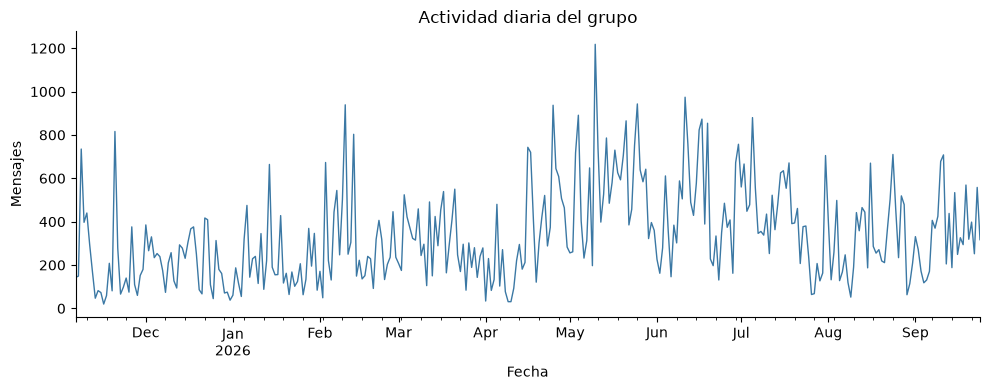

Periodo: 2025-11-06 a 2026-09-24 | Días: 323


In [20]:
tabla_periodo = tabla.loc[tabla["timestamp"] >= inicio_historial].copy()
personas_periodo = tabla_periodo.loc[tabla_periodo["tipo_remitente"].eq("persona")]
calendario = pd.date_range(inicio_historial, tabla_periodo["timestamp"].max().normalize(), freq="D")
actividad_diaria = (personas_periodo.groupby(personas_periodo["timestamp"].dt.normalize())
                   .size().reindex(calendario, fill_value=0).rename("mensajes"))
actividad_diaria.index.name = "fecha"

ax = actividad_diaria.plot(color="#3B78A4", linewidth=1)
ax.set(xlabel="Fecha", ylabel="Mensajes", title="Actividad diaria del grupo")
plt.tight_layout()
plt.show()
print(f"Periodo: {calendario.min().date()} a {calendario.max().date()} | Días: {len(calendario)}")

### 4.2 Días de la semana

,promedio_diario,mensajes,dias_observados
Lunes,333.5,15340,46
Martes,373.3,17172,46
Miércoles,312.8,14387,46
Jueves,357.1,16782,47
Viernes,348.5,16032,46
Sábado,296.6,13645,46
Domingo,336.3,15471,46


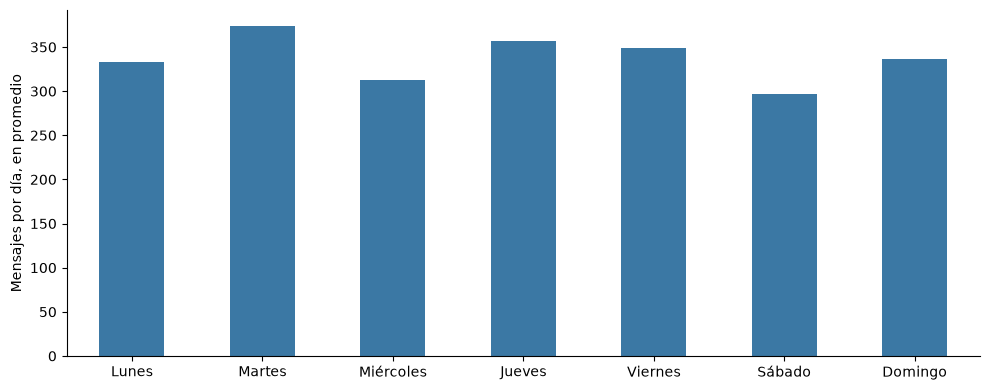

In [21]:
# Filtraremos la actividad agrupándoles por día de las semanas.
actividad_semanal = actividad_diaria.groupby(actividad_diaria.index.dayofweek).agg(["mean", "sum", "size"])
actividad_semanal.columns = ["promedio_diario", "mensajes", "dias_observados"]
actividad_semanal.index = dias
display(actividad_semanal.round(1))

ax = actividad_semanal["promedio_diario"].plot.bar(color="#3B78A4", rot=0)
ax.set(xlabel="", ylabel="Mensajes por día, en promedio")
plt.tight_layout()
plt.show()

**Martes** fue el día más activo, con **373.3 mensajes diarios** en promedio. **Sábado** fue el más tranquilo, con **296.6**. El grupo también conversa bastante los jueves (357.1), mientras que el domingo repunta después de la caída del sábado. Así, la actividad semanal tiene dos picos en martes y jueves; su punto más bajo, el sábado.

### 4.3 Horas del día

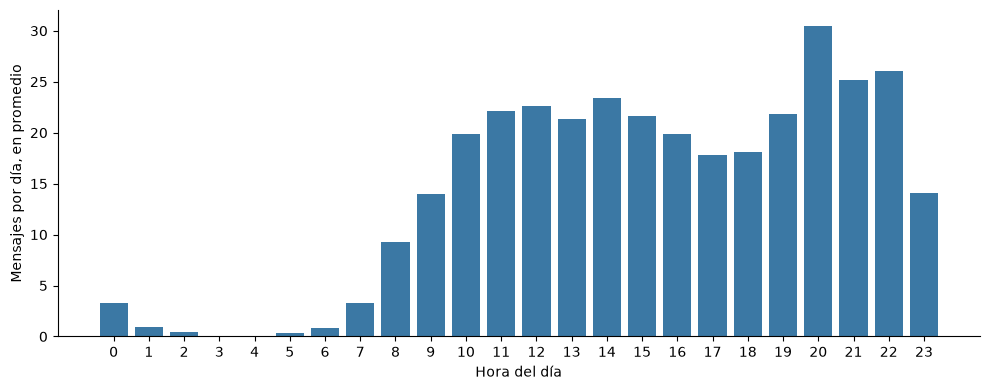

Hora más activa: 20:00
Hora menos activa: 04:00


In [22]:
# Contamos los mensajes de participantes en cada hora del día en las 24 horas que tiene
mensajes_por_hora = (
    tabla_periodo.loc[
        tabla_periodo["tipo_remitente"] == "persona", "timestamp"
    ]
    .dt.hour.value_counts()
    .reindex(range(24), fill_value=0)
    .sort_index()
)

# Expresamos cada hora como promedio por día.
promedio_por_hora = mensajes_por_hora / len(calendario)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(promedio_por_hora.index, promedio_por_hora.values, color="#3B78A4")
ax.set(xlabel="Hora del día", ylabel="Mensajes por día, en promedio")
ax.set_xticks(range(24))
plt.tight_layout()
plt.show()

print(f"Hora más activa: {promedio_por_hora.idxmax():02d}:00")
print(f"Hora menos activa: {promedio_por_hora.idxmin():02d}:00")

La conversación alcanza su punto más alto a las **20:00**, con cerca de **30 mensajes por día** en promedio sobre esa hora. También hay bastante movimiento entre las **10:00 y las 16:00**, pero por la noche el grupo vuelve a cobrar fuerza. La madrugada es mucho más tranquila: las **4:00** son la hora de menor actividad. Las horas corresponden a **Hermosillo (UTC−7)**; la mayoría del grupo se encuentra una hora adelante.

## 5. Vocabulario del grupo

### 5.1 Apariciones y mensajes

En la exploración encontramos un mensaje que repetía una palabra **2,300 veces**. Por eso distinguimos las dos medidas:

| Análisis | Qué se cuenta |
| --- | --- |
| Frecuencia general y nube del grupo | Cada aparición de una palabra |
| Palabras por participante y sus nubes | Mensajes que contienen cada palabra |
| Adjetivos | Mensajes que contienen cada adjetivo, agrupado por lema |

La siguiente comprobación resume la repetición dentro de un mensaje sin mostrar su contenido.

In [23]:
max_repeticiones = sin_enlaces.map(lambda texto: max(Counter(tokenizar(texto)).values(), default=0))
print(f"Máximo de repeticiones de una palabra en un mensaje: {max_repeticiones.max():,}")

Máximo de repeticiones de una palabra en un mensaje: 2,300


Sin mayor contexto, **Kingler** desató un adjetivo, en mayúsculas, 2300 veces contra **Mewtwo** en el mensaje. El *ataque* ha sido muy efectivo si bajar puntos de salud significa provocar la risa de todo el grupo.

### 5.2 Frecuencia general y palabras sin stop words

In [24]:
frecuencias = Counter(p for contenido in sin_enlaces for p in tokenizar(contenido))
# La primera tabla conserva las stop words para mostrar su predominio.
frecuencias_visibles = Counter({p: n for p, n in frecuencias.items() if p not in no_importantes})
mostrar_frecuencias(frecuencias_visibles, "apariciones")

frecuencias_finales = filtrar_frecuencias(frecuencias)
mostrar_frecuencias(frecuencias_finales, "apariciones")

,palabra,apariciones
0,de,24852
1,que,24731
2,a,19539
3,el,19496
4,y,16338
5,la,16008
6,no,15187
7,en,11600
8,se,9966
9,es,9409


,palabra,apariciones
0,pumas,2991
1,wey,2759
2,v***a,2596
3,estupido,2323
4,p**o,2063
5,p*****o,1709
6,pedo,1671
7,dogo,1591
8,madre,1543
9,mensaje,1360


Las palabras gramaticales dominan el conteo inicial. Al retirarlas aparecen **Pumas** y expresiones del habla del grupo, como *wey*. El ranking general conserva las repeticiones dentro de cada mensaje.

### 5.3 Nube general

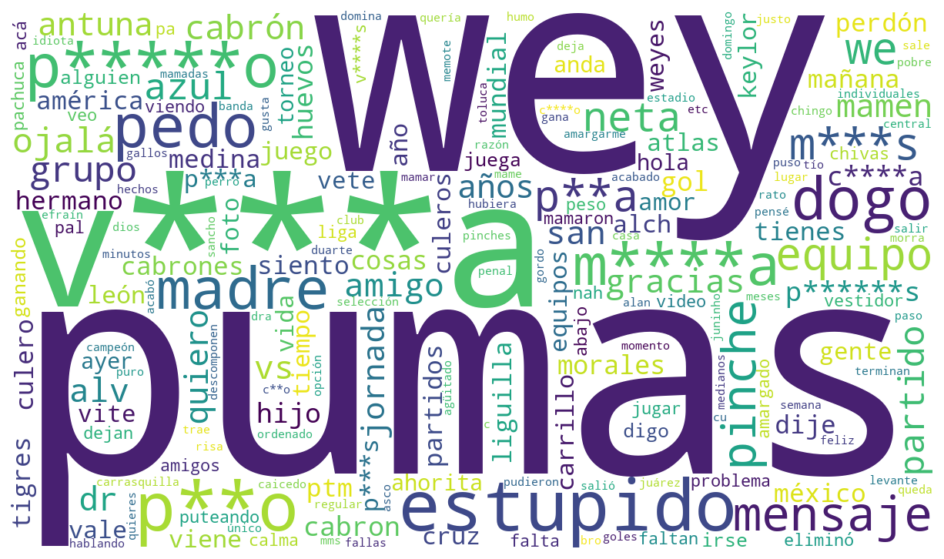

In [25]:
def frecuencias_censuradas(conteo):
    salida = Counter()
    for palabra, cantidad in sorted(conteo.items(), key=lambda par: (-par[1], par[0])):
        salida[censurar(palabra)] += cantidad
    return salida

nube = WordCloud(width=1200, height=700, max_words=200,
                 background_color="white", random_state=42).generate_from_frequencies(
                     frecuencias_censuradas(frecuencias_finales))
plt.figure(figsize=(12, 7))
plt.imshow(nube, interpolation="bilinear")
plt.axis("off")
plt.show()

### 5.4 Palabras por participante

Cada palabra cuenta una vez por mensaje. Los números entre paréntesis indican en cuántos mensajes de esa persona aparece.

In [26]:
frecuencias_por_usuario = {}
for usuario, contenidos in sin_enlaces.groupby(textos["usuario"]):
    conteo = Counter(p for contenido in contenidos for p in sorted(set(tokenizar(contenido))))
    frecuencias_por_usuario[usuario] = filtrar_frecuencias(conteo)

resumen_palabras = pd.DataFrame([
    (usuario, ", ".join(f"{censurar(p)} ({n})" for p, n in
                       sorted(conteo.items(), key=lambda par: (-par[1], par[0]))[:3]))
    for usuario, conteo in frecuencias_por_usuario.items()
], columns=["usuario", "tres_palabras_y_mensajes"])
display(resumen_palabras)

,usuario,tres_palabras_y_mensajes
0,Alakazam,"v***a (56), pinche (37), p**o (35)"
1,Arbok,"siono (71), mensaje (65), pinche (65)"
2,Butterfree,"gracias (10), hermano (4), mil (3)"
3,Cubone,"pumas (53), wey (47), neta (31)"
4,Diglett,"pumas (218), v***a (143), grupo (106)"
5,Doduo,"wey (98), pumas (74), p**o (69)"
6,Electabuzz,"pumas (68), dr (38), cabrón (26)"
7,Gastly,"pumas (8), estadio (5), gordo (5)"
8,Golduck,"pumas (13), gracias (9), m***s (9)"
9,Growlithe,"wey (583), pumas (303), pedo (300)"


**Pumas** aparece entre las palabras más frecuentes de varios participantes. **Lickitung** y **Growlithe** destacan por el uso de *wey*. Los resultados de quienes tienen pocos mensajes describen una muestra mucho menor.

### 5.5 Adjetivos

spaCy identifica los adjetivos y los agrupa por lema; por ejemplo, *grandes* y *grande*. El conteo corresponde a mensajes. La clasificación es automática: en la exploración se descartó una risa que el modelo había etiquetado como adjetivo.

In [27]:
nlp = spacy.load("es_core_news_md", disable=["parser", "ner"])

adjetivos = Counter(
    palabra
    for doc in nlp.pipe(sin_enlaces, batch_size=128)
    for palabra in sorted({
        token.lemma_.casefold()
        for token in doc
        if token.pos_ == "ADJ" and token.is_alpha and not token.is_stop
    })
)

adjetivos = Counter({
    palabra: cantidad
    for palabra, cantidad in adjetivos.items()
    if palabra not in no_importantes
})
adjetivos.pop("jajajajo", None)
adjetivos.pop("alv", None)

top_adjetivos = pd.DataFrame(
    adjetivos.most_common(20),
    columns=["adjetivo", "mensajes"]
)
top_adjetivos["adjetivo"] = top_adjetivos["adjetivo"].map(censurar)

display(top_adjetivos)

,adjetivo,mensajes
0,p**o,487
1,p*****o,374
2,puro,369
3,c****o,323
4,único,302
5,culero,299
6,viejo,218
7,malo,209
8,neto,200
9,acabado,189


Al contar cada adjetivo una sola vez por mensaje, el texto que repetía «estúpido» 2,300 veces deja de dominar el resultado. Entre los adjetivos sin censurar destacan *puro* (369 mensajes), *único* (302), *viejo* (218) y *malo* (209). También son frecuentes varios calificativos altisonantes.

## 6. Pumas y los días con más mensajes

### 6.1 Fechas para investigar

**Pregunta:** ¿los días con más mensajes coinciden con partidos de Pumas? Primero identificamos las diez fechas de mayor actividad y cuántas personas participaron. Después buscaremos el calendario de partidos y otros acontecimientos de esas fechas.

In [28]:
participantes_diarios = (personas_periodo.groupby(personas_periodo["timestamp"].dt.normalize())
                         ["usuario"].nunique().reindex(calendario, fill_value=0))
dias_destacados = actividad_diaria.to_frame().assign(participantes=participantes_diarios)
dias_destacados = (dias_destacados.reset_index().sort_values(
    ["mensajes", "fecha"], ascending=[False, True]).head(10).reset_index(drop=True))
dias_destacados.insert(1, "dia", dias_destacados["fecha"].dt.dayofweek.map(dict(enumerate(dias))))
display(dias_destacados)

,fecha,dia,mensajes,participantes
0,2026-05-10,Domingo,1218,25
1,2026-06-11,Jueves,974,20
2,2026-05-25,Lunes,943,23
3,2026-02-10,Martes,939,22
4,2026-04-25,Sábado,937,23
5,2026-05-04,Lunes,891,20
6,2026-07-05,Domingo,880,19
7,2026-06-17,Miércoles,873,21
8,2026-05-21,Jueves,865,23
9,2026-06-19,Viernes,854,21


### 6.2 ¿Qué pasó en las fechas destacadas? 

Para cada fecha del apartado 6.1 anotaremos el evento encontrado o el contexto. Revisaremos también sucesos fuera de los partidos: fichajes, resultados de otros equipos u otros temas que puedan explicar la conversación. Una coincidencia de fechas se reportará como asociación, sin atribuirle por sí sola la causa del aumento.

In [29]:
eventos = pd.DataFrame([
    ("2026-05-10", "Pumas 3-3 América; avanzó a semifinales"),
    ("2026-06-11", "Partido inaugural del Mundial: jugó México"),
    ("2026-02-10", "Pumas eliminado en Champions vs San Diego"),
    ("2026-05-25", "Día posterior a la final perdida contra Cruz Azul"),
    ("2026-04-25","Pumas vence a Pachuca; queda líder del torneo"),
    ("2026-05-04","América 3-3 Pumas; día posterior"),
    ("2026-07-05","México eliminado del Mundial vs Inglaterra"),
    ("2026-06-17","Día mundialista cargado + Rumores nuevo DT Pumas"),
    ("2026-05-21","Cruz Azul 0-0 Pumas; final de ida"),
    ("2026-06-19","Día mundialista + Confirmación nuevo DT Pumas"),
], columns=["fecha", "evento"])

eventos["fecha"] = pd.to_datetime(eventos["fecha"])

fechas_investigadas = dias_destacados.merge(
    eventos, on="fecha", how="left"
)
fechas_investigadas["evento"] = fechas_investigadas["evento"].fillna(
    "Por investigar"
)

display(fechas_investigadas)

,fecha,dia,mensajes,participantes,evento
0,2026-05-10,Domingo,1218,25,Pumas 3-3 América; avanzó a semifinales
1,2026-06-11,Jueves,974,20,Partido inaugural del Mundial: jugó México
2,2026-05-25,Lunes,943,23,Día posterior a la final perdida contra Cruz Azul
3,2026-02-10,Martes,939,22,Pumas eliminado en Champions vs San Diego
4,2026-04-25,Sábado,937,23,Pumas vence a Pachuca; queda líder del torneo
5,2026-05-04,Lunes,891,20,América 3-3 Pumas; día posterior
6,2026-07-05,Domingo,880,19,México eliminado del Mundial vs Inglaterra
7,2026-06-17,Miércoles,873,21,Día mundialista cargado + Rumores nuevo DT Pumas
8,2026-05-21,Jueves,865,23,Cruz Azul 0-0 Pumas; final de ida
9,2026-06-19,Viernes,854,21,Día mundialista + Confirmación nuevo DT Pumas


El partido celebrado en pleno **Día de las Madres**, hizo que solamente 2 integrantes que estaban en el grupo no participaran ese día. Representando un **92.6%** de participación. No solo eso, dentro del top 10 la diferencia más grande entre puestos contiguos es entre los dos primeros lugares. La razón es que ese partido estuvo lleno de polémica, pasión, momentos de tensión, felicidad, enojo, etc...

Dentro del top 10:
* 4 días donde hubo partido de Pumas
* 2 días donde México jugó en el mundial (primer y último partido del cértamen para el TRI)
* 2 días donde el grupo compartía sus apuestas en jornadas mundialistas interesantes, donde al mismo tiempo los rumores y confirmaciones de un nuevo
  Director Técnico para Pumas se adentraban en la conversación
* 2 días de cruda moral, reflexión y tristeza. Uno en particular cuando Pumas fue incapaz de cortar una racha de 15 años sin coronarse en el máximo campeonato del país

### 6.3 ¿Ha disminuido la actividad del grupo por la final perdida?
Como ya vimos anteriormente, el 24 de mayo fue un día significativo en lo negativo para el club y sus aficionados. Se venía de un periodo de los primeros cinco meses del año donde la expectativa era positiva, pero que con un mal comienzo del equipo desde julio en la nueva temporada que merma las ganas de compartir con los demás del grupo tu sentir.

In [30]:
partidos_pumas = pd.DataFrame([
    # Apertura 2025
    ("2025-11-08", "victoria"),
    ("2025-11-20", "derrota"),

    # Clausura 2026 y Concacaf
    ("2026-01-11", "empate"),
    ("2026-01-14", "victoria"),
    ("2026-01-18", "empate"),
    ("2026-01-30", "victoria"),
    ("2026-02-03", "derrota"),
    ("2026-02-07", "empate"),
    ("2026-02-10", "victoria"),
    ("2026-02-13", "victoria"),
    ("2026-02-22", "victoria"),
    ("2026-02-27", "empate"),
    ("2026-03-03", "derrota"),
    ("2026-03-06", "victoria"),
    ("2026-03-14", "empate"),
    ("2026-03-21", "victoria"),
    ("2026-04-05", "empate"),
    ("2026-04-12", "victoria"),
    ("2026-04-17", "victoria"),
    ("2026-04-21", "victoria"),
    ("2026-04-25", "victoria"),

    # Liguilla
    ("2026-05-03", "empate"),
    ("2026-05-10", "empate"),
    ("2026-05-14", "derrota"),
    ("2026-05-17", "victoria"),
    ("2026-05-21", "empate"),
    ("2026-05-24", "derrota"),

    # Apertura 2026 y Leagues Cup
    ("2026-07-18", "derrota"),
    ("2026-07-21", "victoria"),
    ("2026-07-31", "victoria"),
    ("2026-08-04", "derrota"),
    ("2026-08-07", "derrota"),
    ("2026-08-11", "empate"),  # Perdió en penales ante Columbus    
    ("2026-08-16", "empate"),
    ("2026-08-23", "empate"),
    ("2026-08-28", "derrota"),
    ("2026-09-10", "victoria"),
    ("2026-09-13", "derrota"),
    ("2026-09-19", "empate"),
], columns=["fecha", "resultado"])

partidos_pumas["fecha"] = pd.to_datetime(partidos_pumas["fecha"])

print("Partidos:", len(partidos_pumas))
print(partidos_pumas["resultado"].value_counts())

Partidos: 39
resultado
victoria    16
empate      13
derrota     10
Name: count, dtype: int64


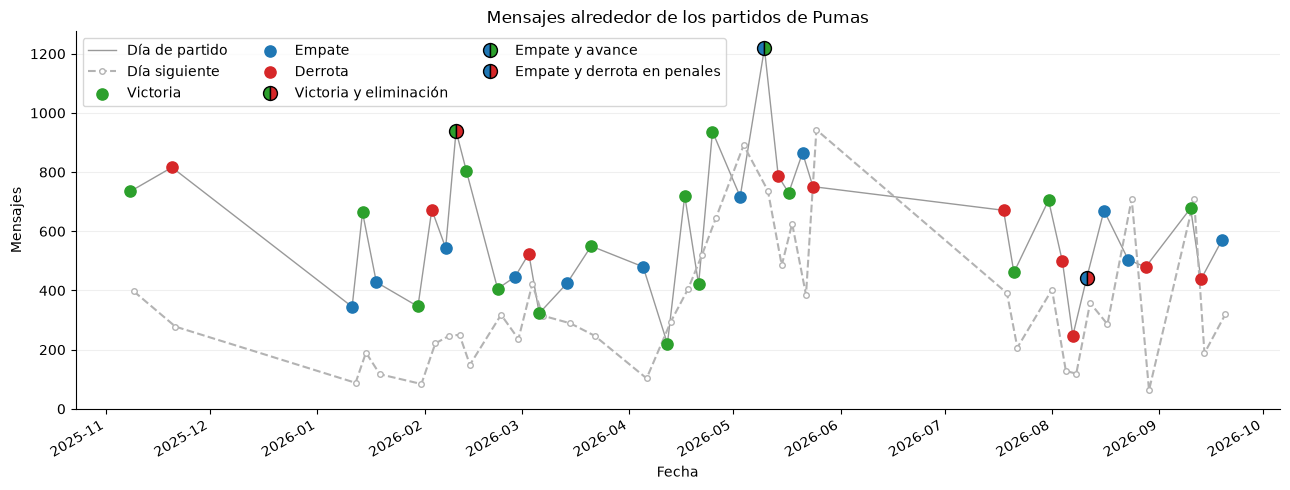

In [31]:
partidos_pumas["mensajes_partido"] = partidos_pumas["fecha"].map(actividad_diaria)
partidos_pumas["fecha_siguiente"] = partidos_pumas["fecha"] + pd.Timedelta(days=1)
partidos_pumas["mensajes_siguiente"] = (
    partidos_pumas["fecha_siguiente"].map(actividad_diaria)
)

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    partidos_pumas["fecha"], partidos_pumas["mensajes_partido"],
    color="0.6", linewidth=1, label="Día de partido"
)
ax.plot(
    partidos_pumas["fecha_siguiente"], partidos_pumas["mensajes_siguiente"],
    color="0.7", linestyle="--", marker="o", markersize=4,
    markerfacecolor="white", label="Día siguiente"
)

colores = {"victoria": "tab:green", "empate": "tab:blue", "derrota": "tab:red"}
especiales = {
    pd.Timestamp("2026-02-10"): ("tab:red", "Victoria y eliminación"),
    pd.Timestamp("2026-05-10"): ("tab:green", "Empate y avance"),
    pd.Timestamp("2026-08-11"): ("tab:red", "Empate y derrota en penales"),
}

for resultado, color in colores.items():
    datos = partidos_pumas.loc[
        partidos_pumas["resultado"].eq(resultado)
        & ~partidos_pumas["fecha"].isin(especiales)
    ]
    ax.scatter(
        datos["fecha"], datos["mensajes_partido"],
        color=color, s=65, label=resultado.capitalize(), zorder=3
    )

for fecha, (color_final, etiqueta) in especiales.items():
    partido = partidos_pumas.loc[
        partidos_pumas["fecha"].eq(fecha)
    ].iloc[0]

    ax.plot(
        [fecha], [partido["mensajes_partido"]],
        linestyle="None", marker="o", markersize=10, fillstyle="left",
        markerfacecolor=colores[partido["resultado"]],
        markerfacecoloralt=color_final, markeredgecolor="black",
        label=etiqueta, zorder=4
    )
ax.set(
    title="Mensajes alrededor de los partidos de Pumas",
    xlabel="Fecha", ylabel="Mensajes"
)
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.2)
ax.legend(ncol=3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [32]:
partidos_pumas["periodo"] = np.where(
    partidos_pumas["fecha"] < "2026-07-01",
    "Hasta mayo",
    "Julio a septiembre"
)

resumen = partidos_pumas.groupby("periodo").agg(
    partidos=("fecha", "size"),
    mediana_partido=("mensajes_partido", "median"),
    mediana_siguiente=("mensajes_siguiente", "median")
)

display(resumen)

,partidos,mediana_partido,mediana_siguiente
periodo,,,
Hasta mayo,27,664.0,295.0
Julio a septiembre,12,501.0,302.5


En los 27 partidos observados hasta mayo, la mediana fue de **664 mensajes** el día del encuentro. En los 12 partidos de julio a septiembre bajó a **501**, cerca de un **25 % menos**. La gráfica muestra fluctuaciones y algunos repuntes, por lo que no se trata de una disminución continua. En cambio, la mediana del día posterior permaneció similar: **295** frente a **302.5** mensajes.

Estos datos muestran menos actividad en los días de partido recientes, pero todavía no permiten atribuir la diferencia al rendimiento de Pumas.

### 6.4 "Domingo, lo dejo todo, me voy a ver a Pumas..."

Es una frase icónica de uno de los cánticos que los aficionados que asisten presencialmente al **Estadio Olímpico Universitario** entonan para apoyar a su equipo. Cabe resaltar, que no todos los Domingos que hay partido de Pumas lo hace como *local*, ni tampoco últimamente ha tenido todos sus partidos como *local* en su propio estadio. También vale la pena resaltar que algunos miembros del grupo asisten a los partidos presencialmente, por lo que su interacción durante el encuentro se ve algo mermada. Sin embargo, el día Domingo se caracteriza por ser un día, para la gran mayoría, despejado para observar el partido en turno.


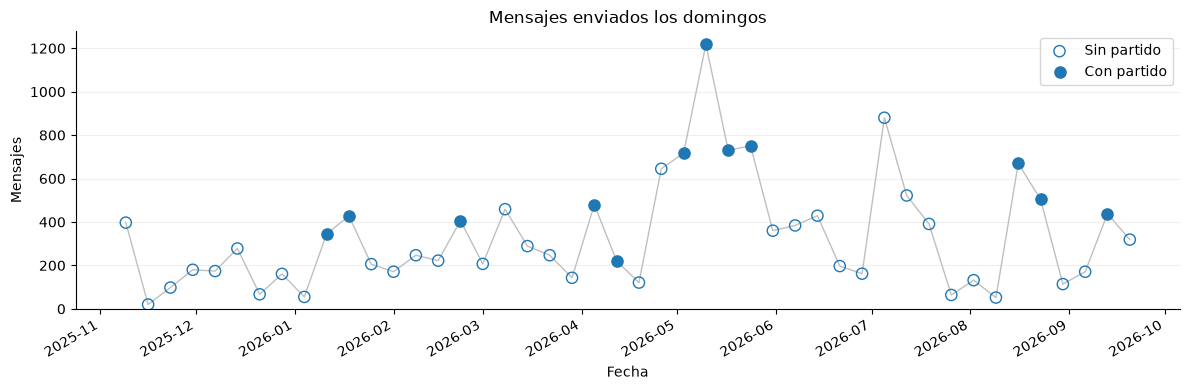

,domingos,mediana
partido,,
Sin partido,34,201.5
Con partido,12,492.0


In [33]:
domingos = actividad_diaria.loc[
    actividad_diaria.index.dayofweek == 6
].to_frame()

domingos["partido"] = domingos.index.isin(partidos_pumas["fecha"])

con_partido = domingos.loc[domingos["partido"]]
sin_partido = domingos.loc[~domingos["partido"]]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(domingos.index, domingos["mensajes"], color="0.75", linewidth=1)

ax.scatter(
    sin_partido.index, sin_partido["mensajes"],
    facecolors="none", edgecolors="tab:blue", s=65,
    label="Sin partido", zorder=3
)
ax.scatter(
    con_partido.index, con_partido["mensajes"],
    color="tab:blue", s=65,
    label="Con partido", zorder=4
)

ax.set(
    title="Mensajes enviados los domingos",
    xlabel="Fecha", ylabel="Mensajes"
)
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

display(
    domingos.groupby("partido")["mensajes"]
    .agg(domingos="size", mediana="median")
    .rename(index={False: "Sin partido", True: "Con partido"})
)

Los **12 domingos con partido de Pumas** registraron una mediana de **492 mensajes**, frente a **201.5** en los **34 domingos sin partido**: alrededor de **2.4 veces más**. Destaca el 10 de mayo, con 1,218 mensajes. También hubo domingos sin partido de Pumas con mucha actividad, así que el calendario del equipo ayuda a explicar la conversación, pero no es el único tema que invita a los participantes a platicar.

## 7. Nubes por persona con siluetas
Para cerrar, veamos de manera bonita las nubes de palabras con las personas que más interactuan en el grupo.

### 7.1 Imágenes y criterios

Las tres nubes serán de **Lickitung, Mewtwo y Growlithe**, los participantes con más mensajes. Usarán las frecuencias por mensaje del apartado 5.4 y un máximo de 200 palabras.

Nos apoyaremos con una libreta de guía del curso.



### 7.2 Generación de las nubes


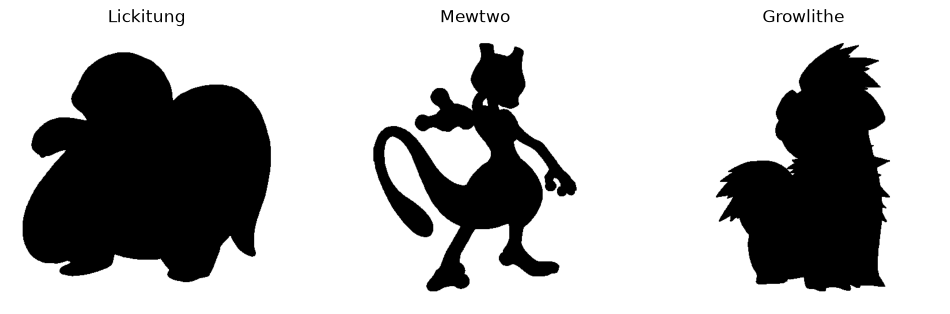

In [34]:
usuarios_nube = ["Lickitung", "Mewtwo", "Growlithe"]
mascaras = {}

fig, ejes = plt.subplots(1, 3, figsize=(12, 4))

for eje, usuario in zip(ejes, usuarios_nube):
    ruta = project_dir / "references" / "siluetas" / f"{usuario.lower()}.png"
    with Image.open(ruta) as imagen:
        alfa = np.asarray(imagen.convert("RGBA").getchannel("A"))

    mascaras[usuario] = np.where(alfa > 10, 0, 255).astype("uint8")
    eje.imshow(mascaras[usuario], cmap="gray", vmin=0, vmax=255)
    eje.set_title(usuario)
    eje.axis("off")

plt.show()

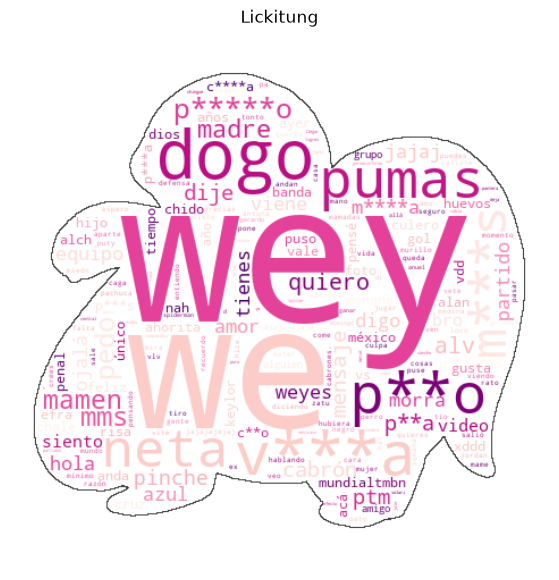

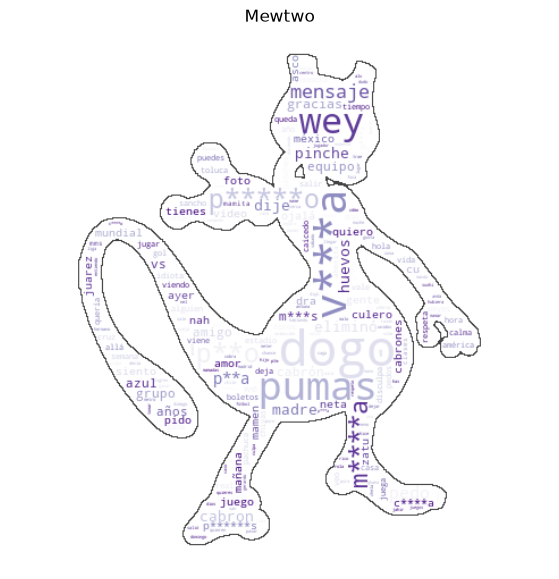

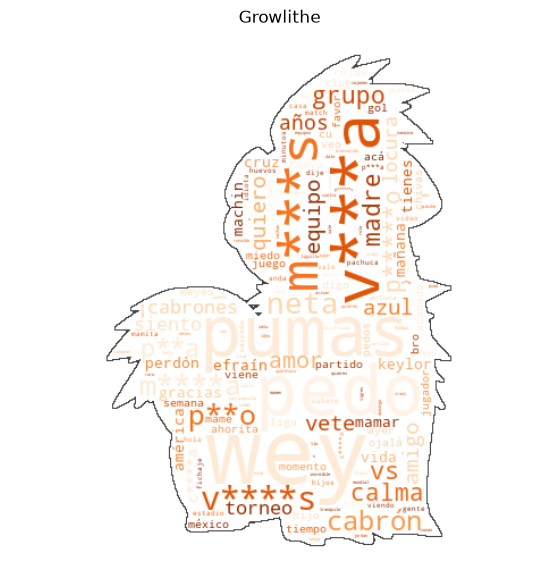

In [35]:
def crear_nube_persona(usuario, colores):
    conteo = frecuencias_censuradas(frecuencias_por_usuario[usuario])

    nube = WordCloud(
        mask=mascaras[usuario],
        max_words=200,
        background_color="white",
        random_state=42,
        colormap=colores,
        contour_width=1,
        contour_color="#444444",
    ).generate_from_frequencies(conteo)

    plt.figure(figsize=(7, 7))
    plt.imshow(nube, interpolation="bilinear")
    plt.title(usuario)
    plt.axis("off")
    plt.show()


for usuario, colores in [
    ("Lickitung", "RdPu"),
    ("Mewtwo", "Purples"),
    ("Growlithe", "Oranges"),
]:
    crear_nube_persona(usuario, colores)

En las tres nubes destacan expresiones coloquiales y referencias a Pumas. En Lickitung sobresalen «wey», «neta» y «pumas»; en Mewtwo, «wey», «eliminó» y varias palabras censuradas; en Growlithe, «pumas», «wey», «pedo» y las risas. Las nubes muestran el vocabulario más frecuente de cada participante, pero el tamaño de las palabras solo se compara dentro de una misma figura.

Growlithe destaca por ser una persona a la que le da risa todo, y risas tan distintas que textualizadas lleva mucho tiempo quitarlas de la nube de palabras debido a sus múltiples combinacions.

## 8. Conclusiones

La participación cambia según la medida: **Lickitung** envió más mensajes y stickers, **Mewtwo** escribió más palabras en total y **Growlithe** usó más emojis. La cantidad de mensajes tampoco parece indicar qué tan largos serán: entre quienes enviaron al menos 1,000 mensajes de texto, la correlación entre ambas medidas fue baja (Spearman = 0.17).

En el historial conservado, los **martes** tuvieron el mayor promedio diario de mensajes y los **sábados**, el menor. La hora de mayor actividad fue las **20:00**, en horario de Hermosillo. Entre los diez días con más mensajes, **cuatro coincidieron con partidos de Pumas**. El máximo ocurrió el **10 de mayo de 2026**, con **1,218 mensajes** de **25 participantes**.

La mediana en días de partido bajó de **664 mensajes** en los 27 encuentros observados hasta mayo a **501** en los 12 de julio a septiembre, una diferencia cercana al **25 %**. No fue una caída continua y la mediana del día posterior se mantuvo parecida (**295** frente a **302.5**). Por otro lado, los domingos con partido registraron una mediana de **492 mensajes**, frente a **201.5** en los domingos sin partido. Los partidos coinciden con mayor conversación dominical, aunque estos datos no demuestran que sean la única causa ni que la baja reciente se deba a los resultados del equipo.

**Pumas** aparece repetidamente en el vocabulario, junto con expresiones coloquiales y palabras altisonantes. Estas últimas se mostraron con asteriscos a partir de una lista definida manualmente. En mi opinión, el lenguaje refleja la confianza entre amigos que llevan años conversando y la forma espontánea en que vivimos el fútbol: algo que parece ser «lo más importante de lo menos importante». Esa es una interpretación personal; las frecuencias de palabras por sí solas no permiten comprobarla.

Me sorprendió que el **24 de mayo**, día de la final, no figurara entre las diez fechas con más mensajes, mientras que el **25 de mayo** sí. La conversación sobre un partido puede continuar al día siguiente; con estos datos no puedo saber si la asistencia al estadio u otros motivos explican esa diferencia.

Quedaría pendiente explorar el vocabulario por temas y, con más datos, intentar un análisis de sentimiento. Finalmente, el estudio describe el historial disponible desde el **6 de noviembre de 2025**, no toda la vida del grupo: los mensajes anteriores no se conservaron después del cambio de celular.